<a href="https://www.kaggle.com/code/lalit7881/beer-profile-rating-prediction?scriptVersionId=369367030" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/stephenpolozoff/top-beer-information/Beer Descriptors Simplified.xlsx
/kaggle/input/datasets/stephenpolozoff/top-beer-information/beer_data_set.csv


In [2]:
# Core analysis stack. A non-interactive backend supports reliable execution in headless environments.
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

RANDOM_STATE = 42

DATA_ROOTS = [
    Path('.'),
    Path('/kaggle/input'),
    Path('/kaggle/input'),
    Path('/kaggle/input/datasets'),
]

def resolve_data_file(file_name=None, suffixes=None):
    """Find the first matching data file under local or Kaggle data roots."""
    suffixes = tuple(suffixes or [])
    for root in DATA_ROOTS:
        if not root.exists():
            continue
        matches = [path for path in root.rglob('*') if path.is_file()]
        if file_name:
            exact_matches = [path for path in matches if path.name == file_name]
            if exact_matches:
                return exact_matches[0]
        if suffixes:
            typed_matches = [path for path in matches if path.suffix.lower() in suffixes]
            if typed_matches:
                return typed_matches[0]
    raise FileNotFoundError(f'Could not resolve data file: {file_name or suffixes}')

csv_path = resolve_data_file(file_name='beer_data_set.csv', suffixes=['.csv'])
xlsx_path = resolve_data_file(file_name='Beer Descriptors Simplified.xlsx', suffixes=['.xlsx', '.xls'])

print(f'Beer dataset: {csv_path}')
print(f'Descriptor reference: {xlsx_path}')

Beer dataset: /kaggle/input/datasets/stephenpolozoff/top-beer-information/beer_data_set.csv
Descriptor reference: /kaggle/input/datasets/stephenpolozoff/top-beer-information/Beer Descriptors Simplified.xlsx


In [3]:
df_raw = pd.read_csv(csv_path)
descriptor_df = pd.read_excel(xlsx_path)

print(f'Main dataset shape: {df_raw.shape}')
print(f'Descriptor reference shape: {descriptor_df.shape}')
display(df_raw.head())
display(descriptor_df.head())

Main dataset shape: (5558, 21)
Descriptor reference shape: (97, 6)


,Name,key,Style,Style Key,Brewery,Description,ABV,Ave Rating,Min IBU,Max IBU,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty
0,Amber,251,Altbier,8,Alaskan Brewing Co.,"Notes:Richly malty and long on the palate, wit...",5.300,3.650,25,50,13,32,9,47,74,33,0,33,57,8,111
1,Double Bag,252,Altbier,8,Long Trail Brewing Co.,"Notes:This malty, full-bodied double alt is al...",7.200,3.900,25,50,12,57,18,33,55,16,0,24,35,12,84
2,Long Trail Ale,253,Altbier,8,Long Trail Brewing Co.,Notes:Long Trail Ale is a full-bodied amber al...,5.000,3.580,25,50,14,37,6,42,43,11,0,10,54,4,62
3,Doppelsticke,254,Altbier,8,Uerige Obergärige Hausbrauerei,Notes:,8.500,4.150,25,50,13,55,31,47,101,18,1,49,40,16,119
4,Scurry,255,Altbier,8,Off Color Brewing,Notes:Just cause it's dark and German doesn't ...,5.300,3.670,25,50,21,69,10,63,120,14,0,19,36,15,218


,Astringent,Impact,Body,Impact.1,Alcoholic,Impact.2
0,acetic,1.000,acacia,1,absinthe,1.000
1,acid,1.000,acasia,1,agave,1.000
2,acidic,1.000,amaranth,1,alcohol,1.000
3,acidified,1.000,amargor,1,alcoholic,1.000
4,acidifying,1.000,big,1,alcoholized,1.000


In [4]:
audit = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_count': df_raw.isna().sum(),
    'missing_pct': (df_raw.isna().mean() * 100).round(2),
    'unique_values': df_raw.nunique(dropna=False)
}).sort_values(['missing_count', 'unique_values'], ascending=[False, False])

display(audit)
print(f'Exact duplicate rows: {df_raw.duplicated().sum():,}')
print(f'Unique beer names: {df_raw["Name"].nunique(dropna=True):,}')
print(f'Unique breweries: {df_raw["Brewery"].nunique(dropna=True):,}')
display(df_raw.describe(include='all').T)

,dtype,missing_count,missing_pct,unique_values
Name,object,2,0.040,5318
key,int64,0,0.000,5558
Description,object,0,0.000,3347
Brewery,object,0,0.000,1498
Ave Rating,float64,0,0.000,289
ABV,float64,0,0.000,229
Sour,int64,0,0.000,222
Malty,int64,0,0.000,217
Sweet,int64,0,0.000,191
Fruits,int64,0,0.000,185


Exact duplicate rows: 0
Unique beer names: 5,317
Unique breweries: 1,498


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,5556,5317,Oktoberfest,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
key,"5,558.000",NaN,NaN,NaN,"2,779.500","1,604.601",1.000,"1,390.250","2,779.500","4,168.750","5,558.000"
Style,5558,112,Altbier,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Style Key,"5,558.000",NaN,NaN,NaN,64.449,35.815,2.000,34.000,64.000,95.000,126.000
Brewery,5558,1498,Boston Beer Company (Samuel Adams),81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,5558,3347,Notes:,2196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ABV,"5,558.000",NaN,NaN,NaN,6.634,2.522,0.000,5.000,6.000,7.900,57.500
Ave Rating,"5,558.000",NaN,NaN,NaN,3.760,0.443,1.270,3.590,3.820,4.040,4.830
Min IBU,"5,558.000",NaN,NaN,NaN,20.716,13.737,0.000,10.000,20.000,25.000,65.000
Max IBU,"5,558.000",NaN,NaN,NaN,38.452,22.185,0.000,25.000,35.000,45.000,100.000


In [5]:
df = df_raw.copy()

# Normalize text while preserving genuinely missing values.
text_columns = ['Name', 'Style', 'Brewery', 'Description']
for column in text_columns:
    if column in df.columns:
        df[column] = df[column].astype('string').str.strip()
        df[column] = df[column].replace({'': pd.NA, 'nan': pd.NA, 'None': pd.NA})

# Explicit conversion makes the notebook robust to alternate CSV type inference.
expected_numeric = [
    'key', 'Style Key', 'ABV', 'Ave Rating', 'Min IBU', 'Max IBU',
    'Astringency', 'Body', 'Alcohol', 'Bitter', 'Sweet', 'Sour',
    'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty'
]
for column in expected_numeric:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors='coerce')

rows_before = len(df)
df = df.drop_duplicates().copy()
print(f'Removed {rows_before - len(df):,} exact duplicate rows.')

if {'Min IBU', 'Max IBU'}.issubset(df.columns):
    df['IBU Midpoint'] = df[['Min IBU', 'Max IBU']].mean(axis=1)
    df['IBU Range'] = df['Max IBU'] - df['Min IBU']
    invalid_ibu = df['Min IBU'] > df['Max IBU']
    print(f'Rows with Min IBU greater than Max IBU: {invalid_ibu.sum():,}')
    # Retain records but avoid treating an invalid range as a valid measurement.
    df.loc[invalid_ibu, ['IBU Midpoint', 'IBU Range']] = np.nan

if 'Ave Rating' in df.columns:
    out_of_range = ~df['Ave Rating'].between(0, 5) & df['Ave Rating'].notna()
    print(f'Ratings outside the conventional [0, 5] interval: {out_of_range.sum():,}')

display(df.head())
display(df.isna().mean().mul(100).sort_values(ascending=False).to_frame('missing_pct'))

Removed 0 exact duplicate rows.
Rows with Min IBU greater than Max IBU: 0
Ratings outside the conventional [0, 5] interval: 0


,Name,key,Style,Style Key,Brewery,Description,ABV,Ave Rating,Min IBU,Max IBU,Astringency,Body,Alcohol,Bitter,Sweet,Sour,Salty,Fruits,Hoppy,Spices,Malty,IBU Midpoint,IBU Range
0,Amber,251,Altbier,8,Alaskan Brewing Co.,"Notes:Richly malty and long on the palate, wit...",5.300,3.650,25,50,13,32,9,47,74,33,0,33,57,8,111,37.500,25.000
1,Double Bag,252,Altbier,8,Long Trail Brewing Co.,"Notes:This malty, full-bodied double alt is al...",7.200,3.900,25,50,12,57,18,33,55,16,0,24,35,12,84,37.500,25.000
2,Long Trail Ale,253,Altbier,8,Long Trail Brewing Co.,Notes:Long Trail Ale is a full-bodied amber al...,5.000,3.580,25,50,14,37,6,42,43,11,0,10,54,4,62,37.500,25.000
3,Doppelsticke,254,Altbier,8,Uerige Obergärige Hausbrauerei,Notes:,8.500,4.150,25,50,13,55,31,47,101,18,1,49,40,16,119,37.500,25.000
4,Scurry,255,Altbier,8,Off Color Brewing,Notes:Just cause it's dark and German doesn't ...,5.300,3.670,25,50,21,69,10,63,120,14,0,19,36,15,218,37.500,25.000


,missing_pct
Name,0.036
key,0.000
Style,0.000
Style Key,0.000
Brewery,0.000
Description,0.000
ABV,0.000
Ave Rating,0.000
Min IBU,0.000
Max IBU,0.000


## EDA

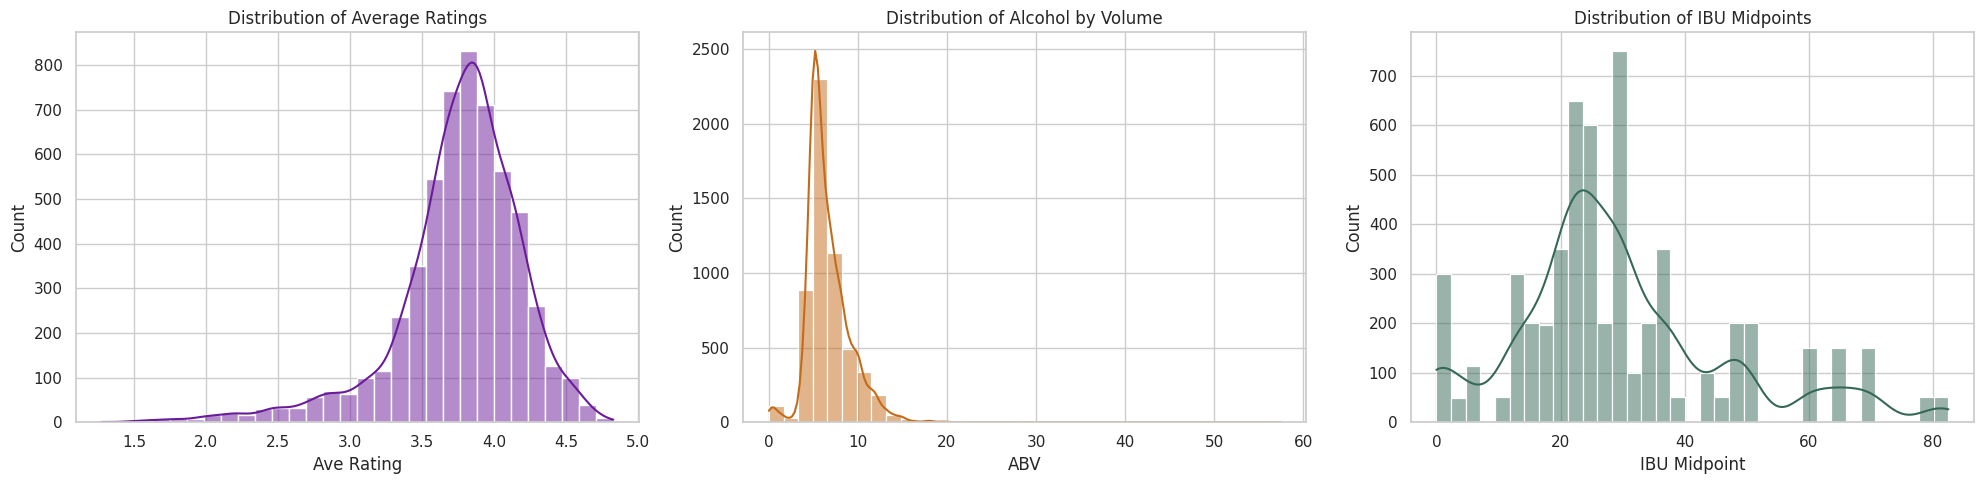

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sns.histplot(data=df, x='Ave Rating', bins=30, kde=True, color='#6A1B9A', ax=axes[0])
axes[0].set_title('Distribution of Average Ratings')

sns.histplot(data=df, x='ABV', bins=35, kde=True, color='#C46B1A', ax=axes[1])
axes[1].set_title('Distribution of Alcohol by Volume')

sns.histplot(data=df, x='IBU Midpoint', bins=35, kde=True, color='#356859', ax=axes[2])
axes[2].set_title('Distribution of IBU Midpoints')

plt.tight_layout()
plt.show()

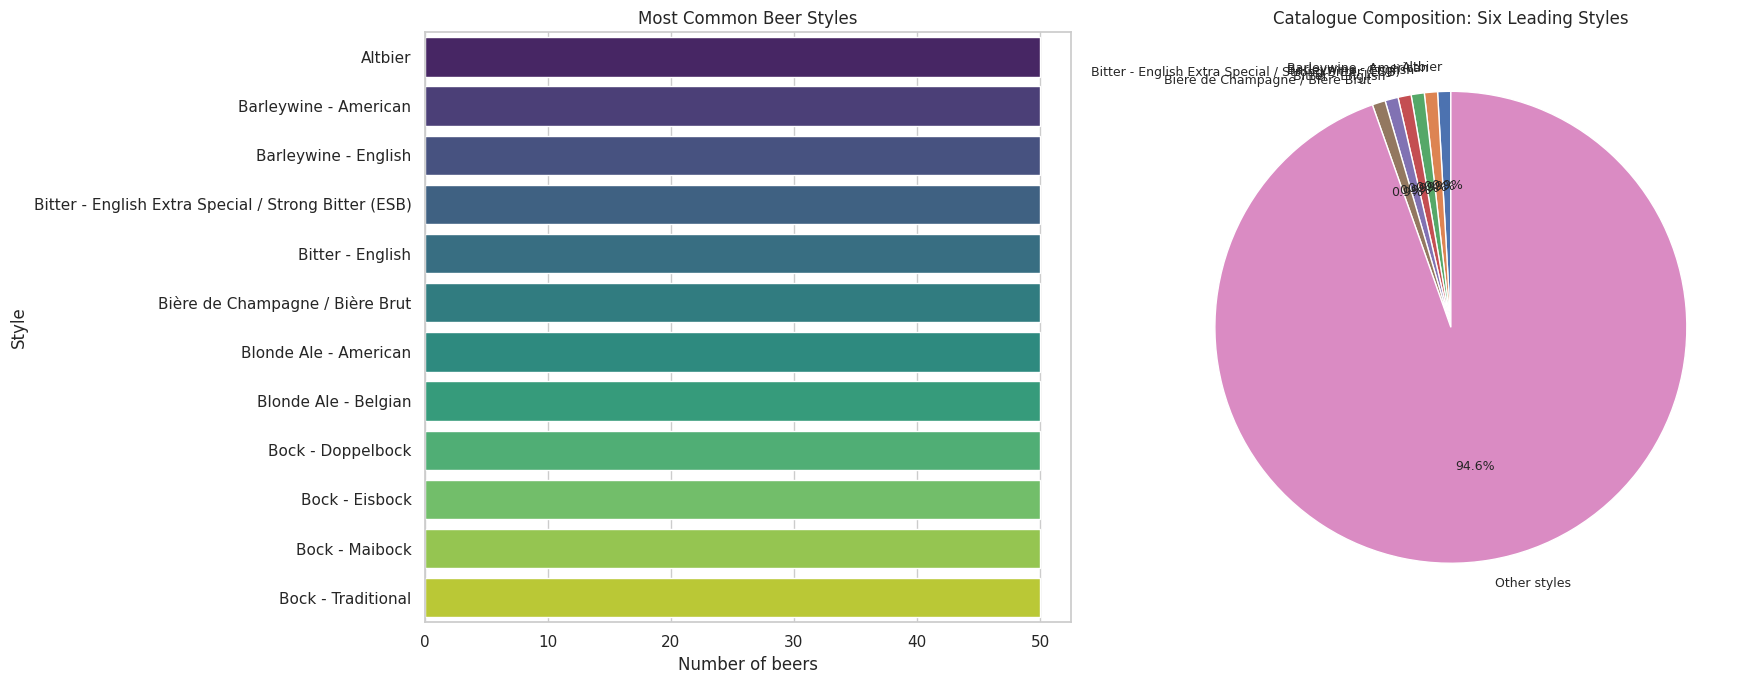

In [7]:
top_styles = df['Style'].value_counts().head(12).index
style_counts = df['Style'].value_counts().loc[top_styles].sort_values()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.countplot(
    data=df[df['Style'].isin(top_styles)], y='Style', order=style_counts.index,
    hue='Style', legend=False, palette='viridis', ax=axes[0]
)
axes[0].set_title('Most Common Beer Styles')
axes[0].set_xlabel('Number of beers')
axes[0].set_ylabel('Style')

# A pie is used only for a deliberately compact high-level composition view.
top_style_share = df['Style'].value_counts().head(6)
other_count = len(df) - top_style_share.sum()
pie_values = pd.concat([top_style_share, pd.Series({'Other styles': other_count})])
axes[1].pie(pie_values, labels=pie_values.index, autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 9})
axes[1].set_title('Catalogue Composition: Six Leading Styles')

plt.tight_layout()
plt.show()

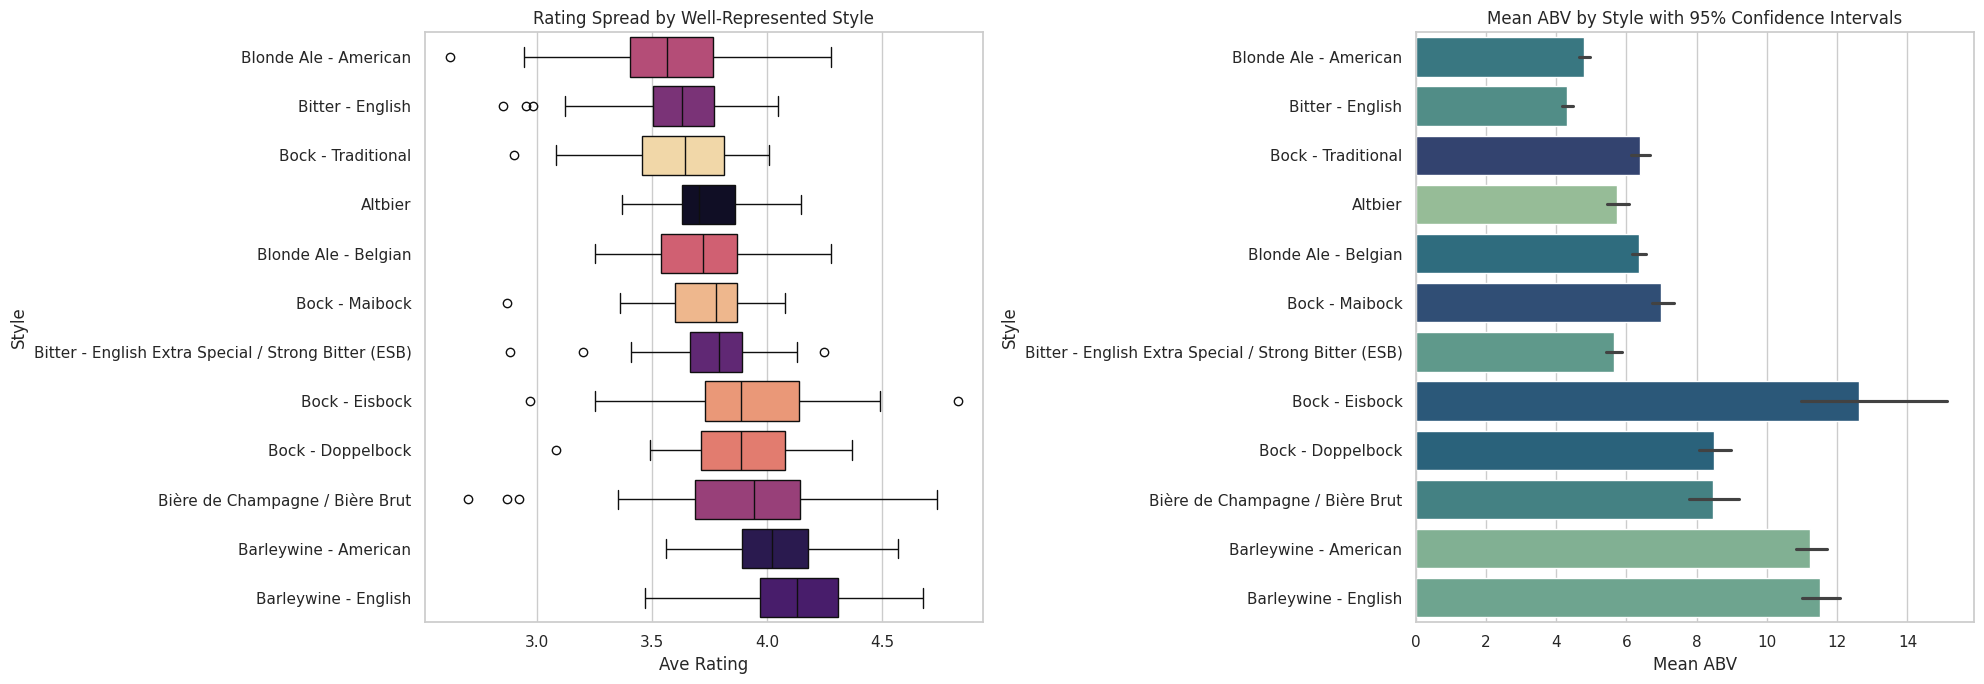

In [8]:
eligible_style_counts = df['Style'].value_counts()
eligible_styles = eligible_style_counts[eligible_style_counts >= 20].head(12).index
plot_df = df[df['Style'].isin(eligible_styles)].copy()
style_order = plot_df.groupby('Style')['Ave Rating'].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
sns.boxplot(data=plot_df, y='Style', x='Ave Rating', order=style_order, hue='Style',
            legend=False, palette='magma', ax=axes[0])
axes[0].set_title('Rating Spread by Well-Represented Style')

sns.barplot(data=plot_df, y='Style', x='ABV', order=style_order, estimator=np.mean,
            errorbar=('ci', 95), hue='Style', legend=False, palette='crest', ax=axes[1])
axes[1].set_title('Mean ABV by Style with 95% Confidence Intervals')
axes[1].set_xlabel('Mean ABV')

plt.tight_layout()
plt.show()

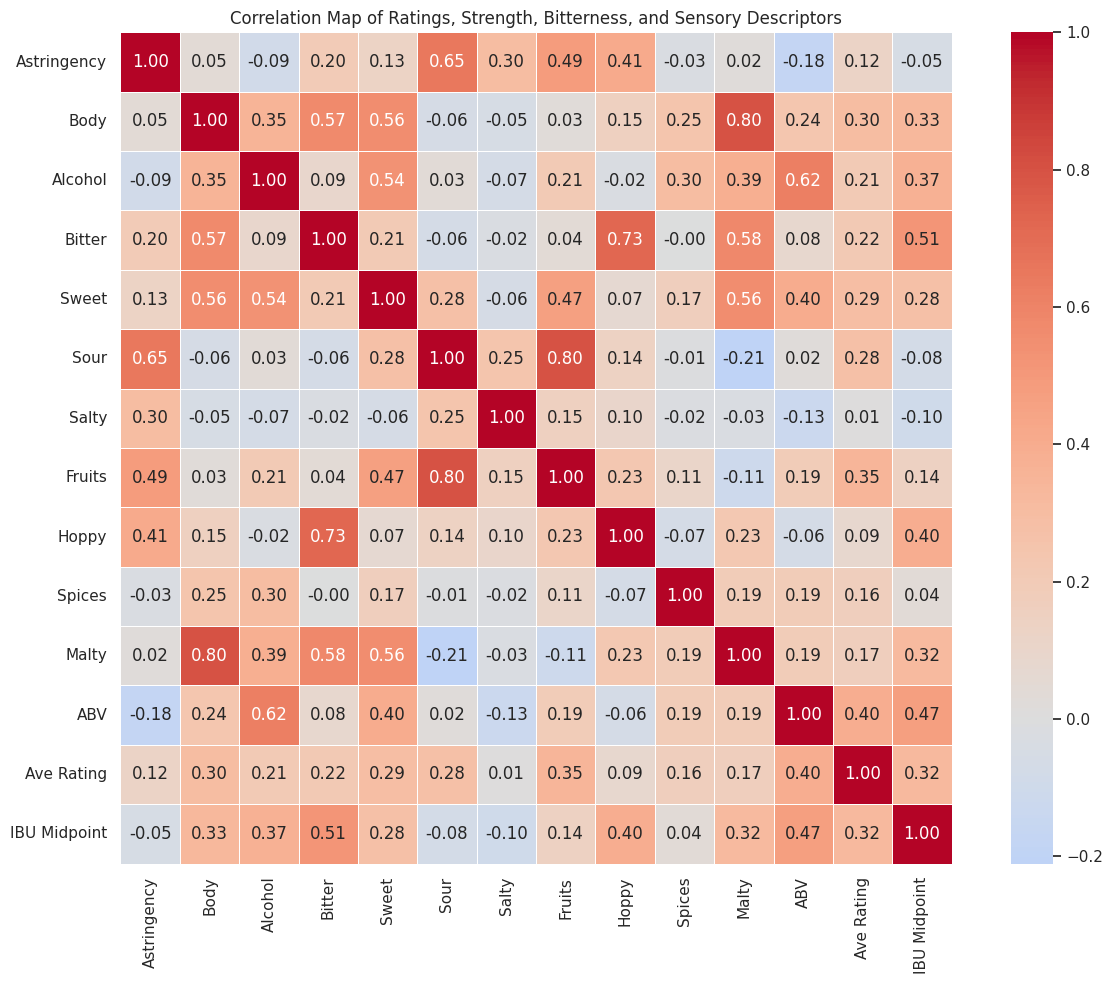

In [9]:
sensory_columns = [
    'Astringency', 'Body', 'Alcohol', 'Bitter', 'Sweet', 'Sour',
    'Salty', 'Fruits', 'Hoppy', 'Spices', 'Malty'
]
sensory_columns = [column for column in sensory_columns if column in df.columns]

# Restrict correlation analysis explicitly to numeric variables.
numeric_df = df.select_dtypes(include=[np.number])
correlation_columns = [
    column for column in sensory_columns + ['ABV', 'Ave Rating', 'IBU Midpoint']
    if column in numeric_df.columns
]

if len(correlation_columns) >= 4:
    plt.figure(figsize=(13, 10))
    sns.heatmap(df[correlation_columns].corr(), annot=True, fmt='.2f', cmap='coolwarm',
                center=0, square=True, linewidths=.5)
    plt.title('Correlation Map of Ratings, Strength, Bitterness, and Sensory Descriptors')
    plt.tight_layout()
    plt.show()
else:
    print('Fewer than four numeric analysis columns are available, so the correlation heatmap is skipped.')


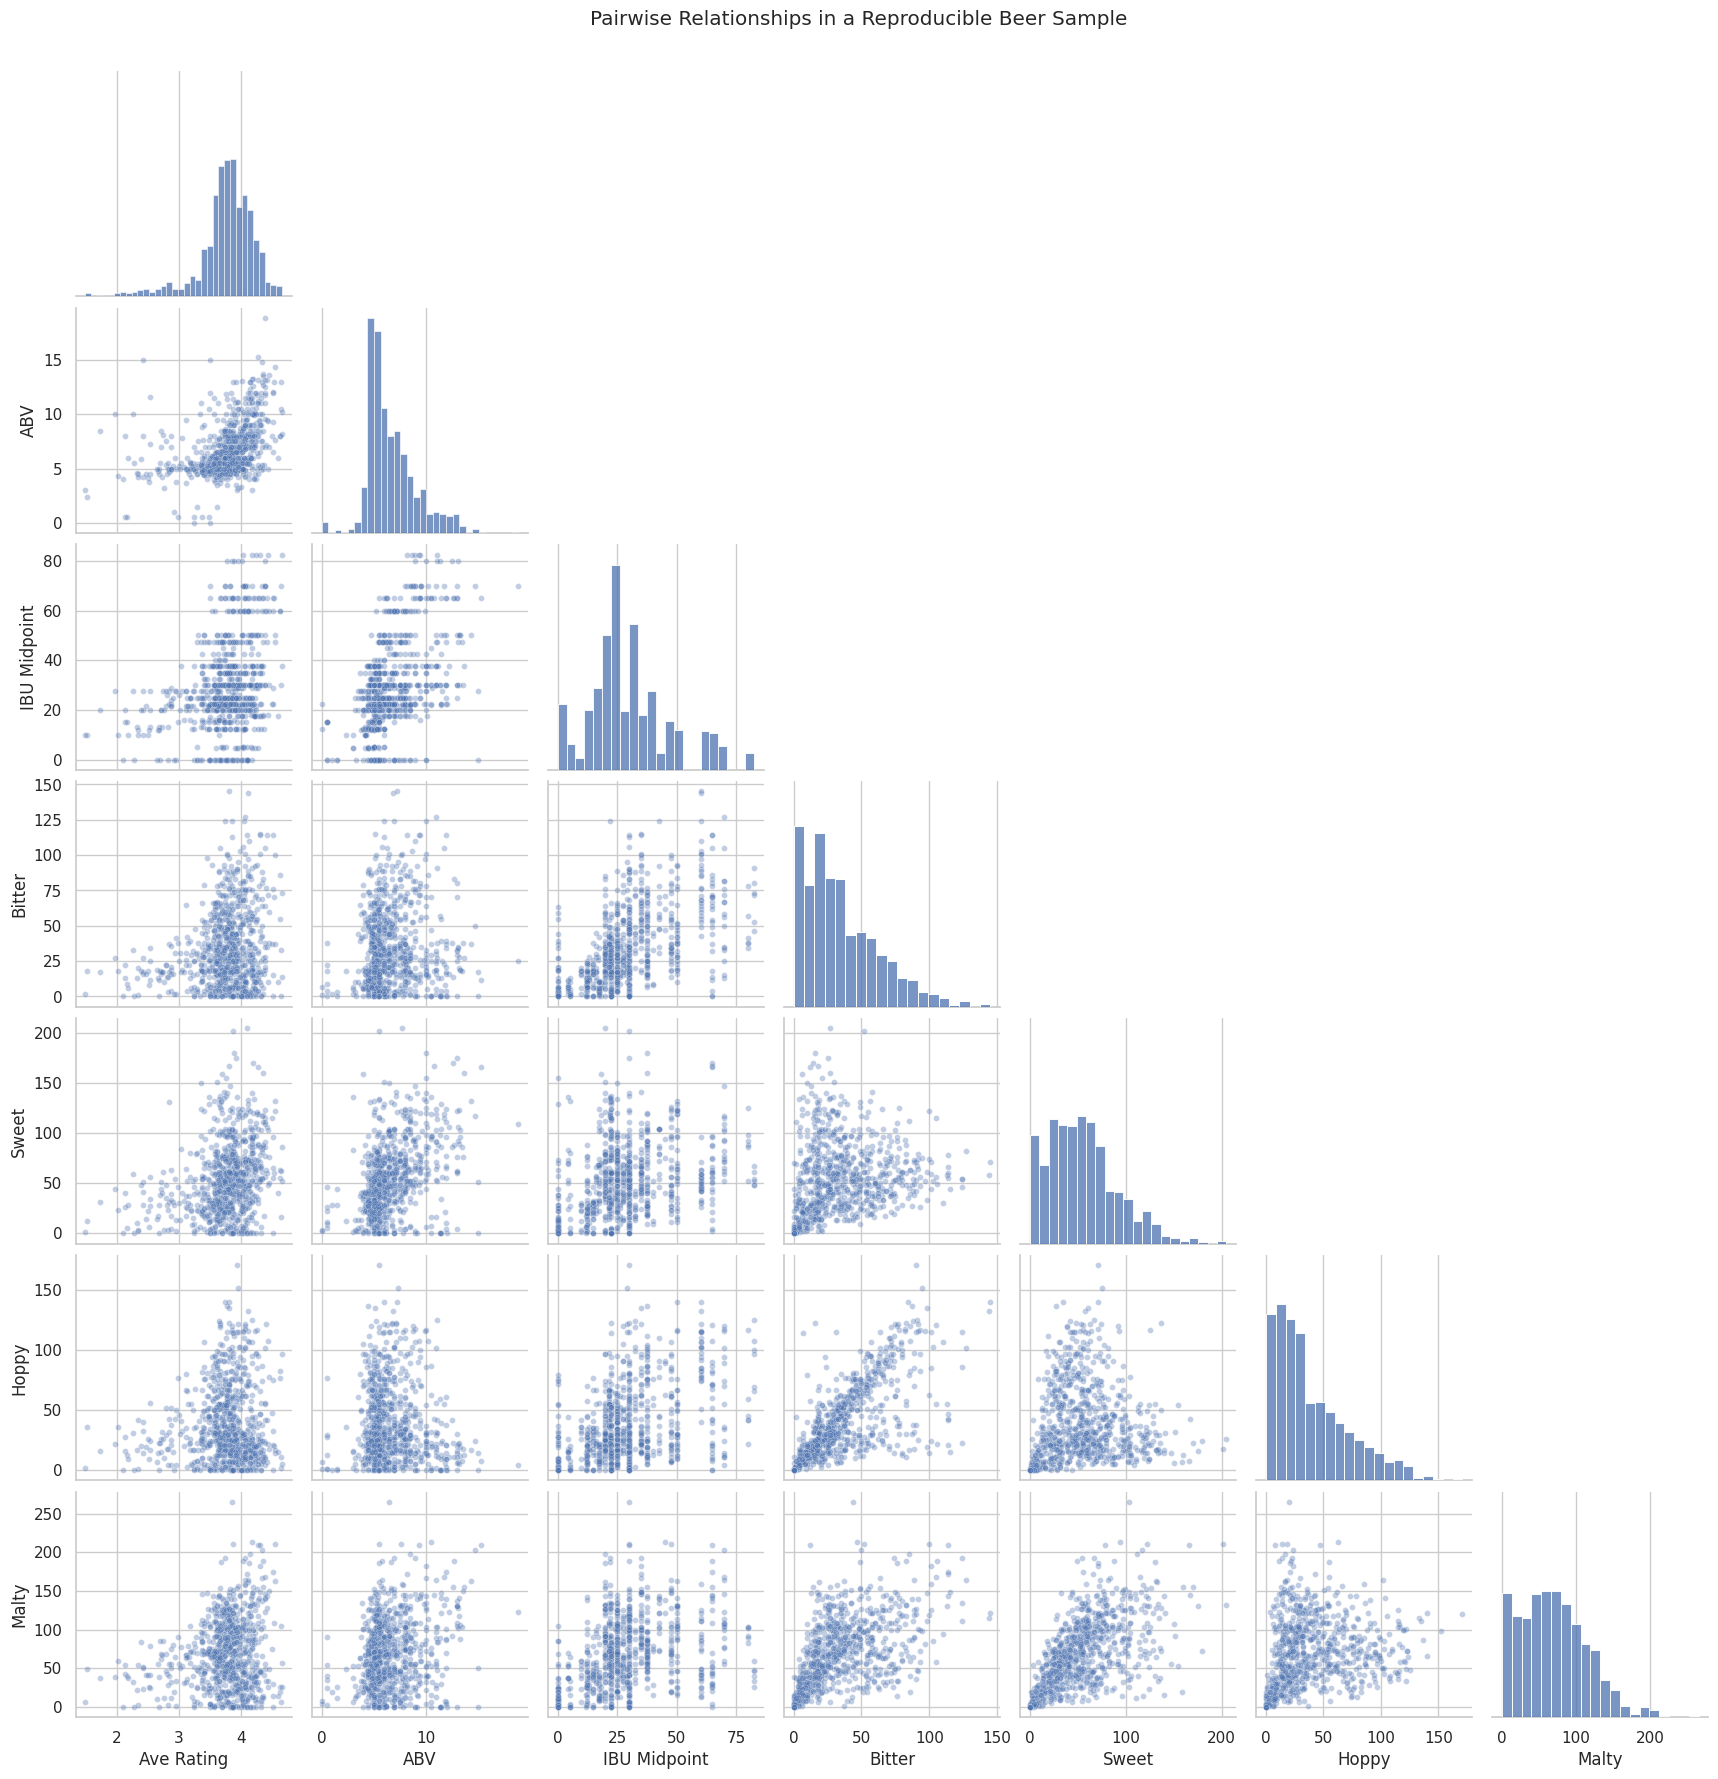

In [10]:
pair_columns = [
    column for column in ['Ave Rating', 'ABV', 'IBU Midpoint', 'Bitter', 'Sweet', 'Hoppy', 'Malty']
    if column in df.columns
]
complete_pair_df = df[pair_columns].dropna()

# Sampling prevents a pair plot from becoming needlessly expensive on larger future versions.
if len(pair_columns) >= 4 and len(complete_pair_df) >= 2:
    pair_df = complete_pair_df.sample(n=min(800, len(complete_pair_df)), random_state=RANDOM_STATE)
    pair_grid = sns.pairplot(pair_df, corner=True, diag_kind='hist', plot_kws={'alpha': 0.35, 's': 18})
    pair_grid.fig.suptitle('Pairwise Relationships in a Reproducible Beer Sample', y=1.02)
    plt.show()
else:
    print('Insufficient complete rows for a pair plot.')

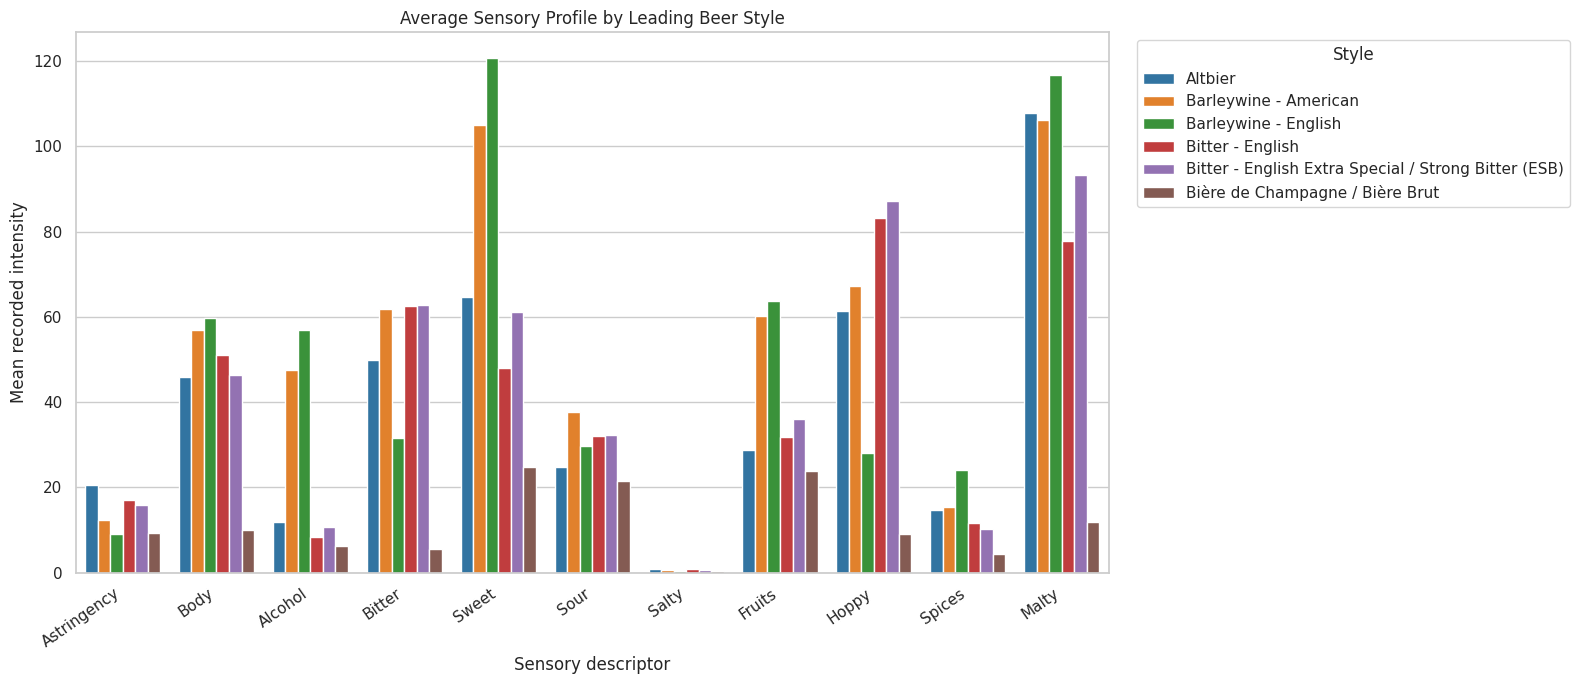

In [11]:
profile_styles = df['Style'].value_counts().head(6).index
profile_long = (
    df[df['Style'].isin(profile_styles)]
    .groupby('Style')[sensory_columns].mean()
    .reset_index()
    .melt(id_vars='Style', var_name='Descriptor', value_name='Mean intensity')
)

plt.figure(figsize=(16, 7))
sns.barplot(data=profile_long, x='Descriptor', y='Mean intensity', hue='Style', palette='tab10')
plt.title('Average Sensory Profile by Leading Beer Style')
plt.xlabel('Sensory descriptor')
plt.ylabel('Mean recorded intensity')
plt.xticks(rotation=35, ha='right')
plt.legend(title='Style', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

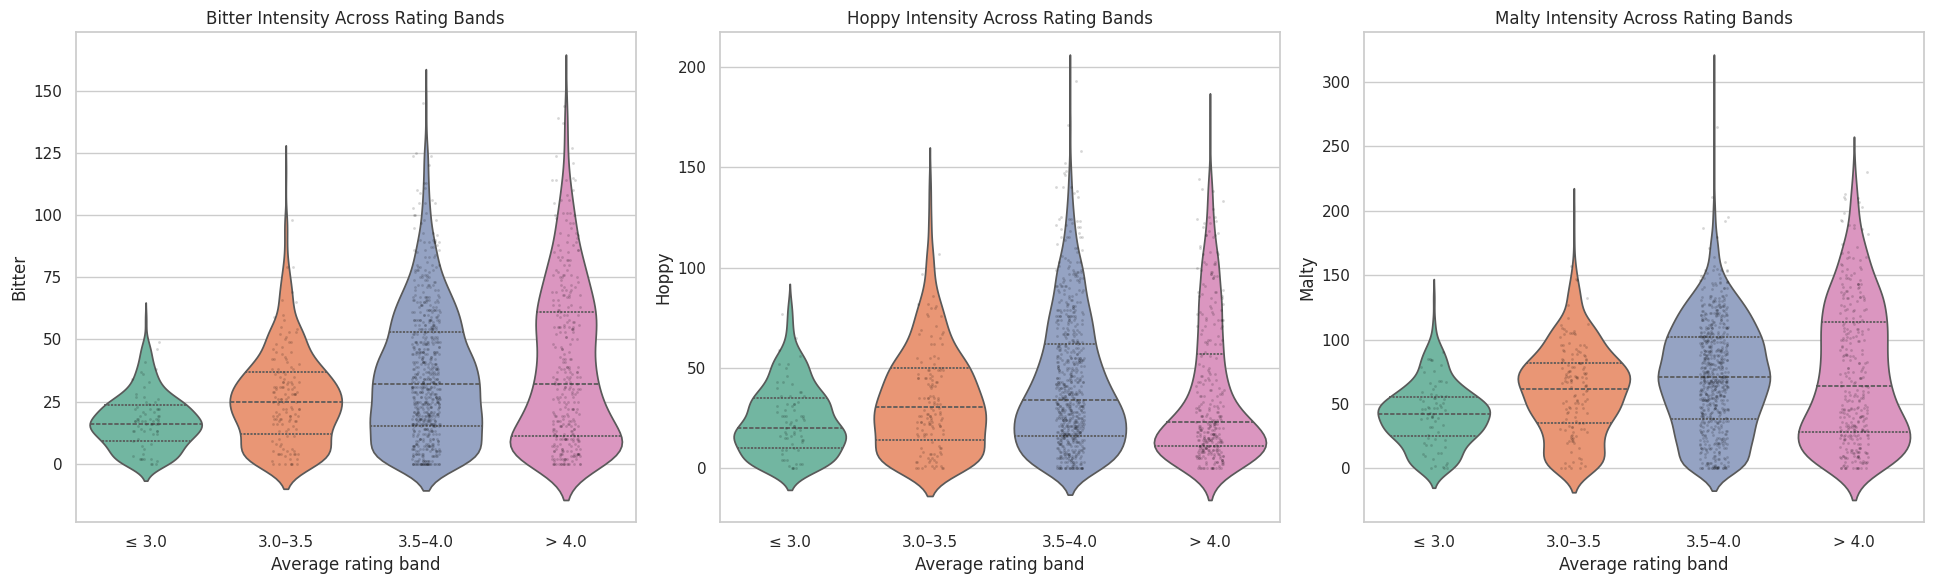

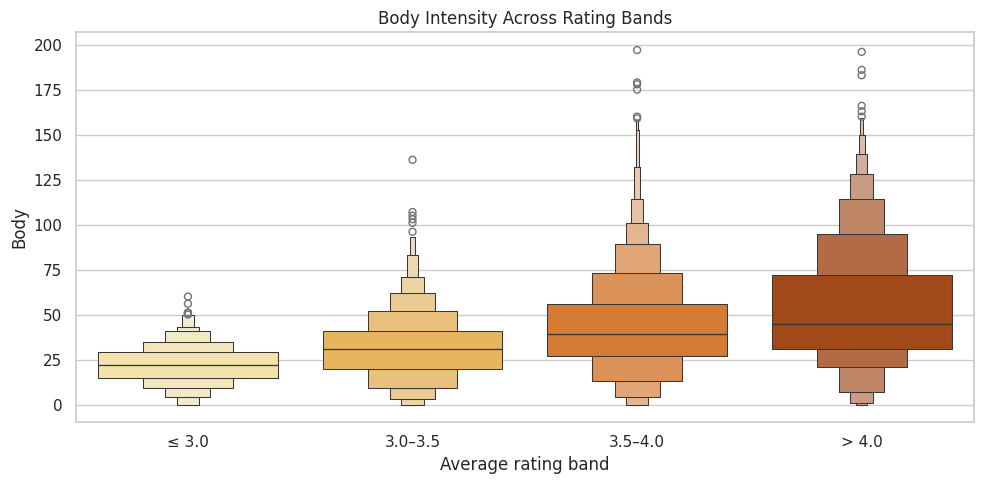

In [12]:
rating_band = pd.cut(
    df['Ave Rating'], bins=[-np.inf, 3.0, 3.5, 4.0, np.inf],
    labels=['≤ 3.0', '3.0–3.5', '3.5–4.0', '> 4.0']
)
rating_plot = df.assign(Rating_Band=rating_band)
descriptor_choices = [column for column in ['Bitter', 'Hoppy', 'Malty'] if column in df.columns]

if descriptor_choices:
    fig, axes = plt.subplots(1, len(descriptor_choices), figsize=(6.5 * len(descriptor_choices), 6))
    if len(descriptor_choices) == 1:
        axes = [axes]
    strip_sample = rating_plot.sample(n=min(1200, len(rating_plot)), random_state=RANDOM_STATE)
    for axis, descriptor in zip(axes, descriptor_choices):
        sns.violinplot(data=rating_plot, x='Rating_Band', y=descriptor, inner='quartile',
                       hue='Rating_Band', legend=False, palette='Set2', ax=axis)
        sns.stripplot(data=strip_sample, x='Rating_Band', y=descriptor, color='black',
                      alpha=.16, size=2, ax=axis)
        axis.set_title(f'{descriptor} Intensity Across Rating Bands')
        axis.set_xlabel('Average rating band')
    plt.tight_layout()
    plt.show()

if 'Body' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.boxenplot(data=rating_plot, x='Rating_Band', y='Body', hue='Rating_Band',
                  legend=False, palette='YlOrBr')
    plt.title('Body Intensity Across Rating Bands')
    plt.xlabel('Average rating band')
    plt.tight_layout()
    plt.show()


In [13]:
target = 'Ave Rating'
numeric_features = [
    column for column in sensory_columns + ['ABV', 'Min IBU', 'Max IBU', 'IBU Midpoint', 'IBU Range']
    if column in df.columns
]
categorical_features = [column for column in ['Style'] if column in df.columns]
model_features = numeric_features + categorical_features

model_df = df[model_features + [target]].dropna(subset=[target]).copy()
X = model_df[model_features]
y = model_df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)
])

model = RandomForestRegressor(
    n_estimators=350,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rating_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', model)
])

rating_pipeline.fit(X_train, y_train)
predictions = rating_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
# sklearn versions differ: some no longer accept squared=False in mean_squared_error.
# Taking the square root explicitly is version-compatible and yields the same RMSE.
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)
cv_r2 = cross_val_score(rating_pipeline, X_train, y_train, cv=5, scoring='r2', n_jobs=-1)

print(f'Held-out MAE:  {mae:.3f} rating points')
print(f'Held-out RMSE: {rmse:.3f} rating points')
print(f'Held-out R²:   {r2:.3f}')
print(f'5-fold CV R²:  {cv_r2.mean():.3f} ± {cv_r2.std():.3f}')
print(f'Training rows: {len(X_train):,} | Test rows: {len(X_test):,}')

Held-out MAE:  0.177 rating points
Held-out RMSE: 0.241 rating points
Held-out R²:   0.683
5-fold CV R²:  0.666 ± 0.017
Training rows: 4,446 | Test rows: 1,112


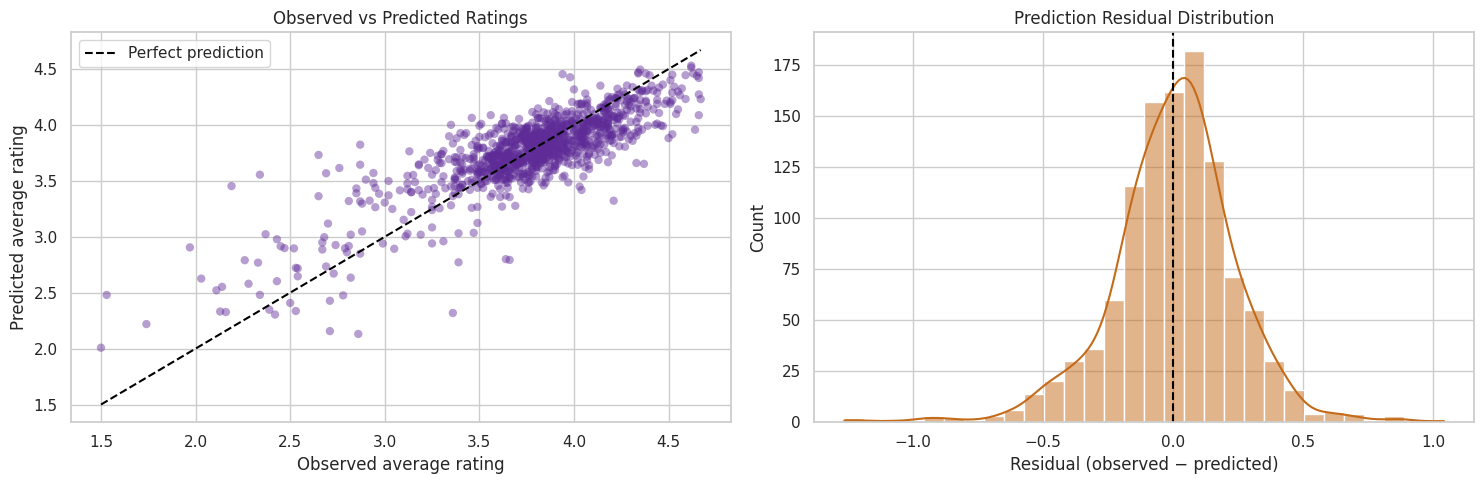

In [14]:
residuals = y_test - predictions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, predictions, alpha=.45, color='#5E2B97', edgecolor='none')
limits = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
axes[0].plot(limits, limits, '--', color='black', label='Perfect prediction')
axes[0].set_xlabel('Observed average rating')
axes[0].set_ylabel('Predicted average rating')
axes[0].set_title('Observed vs Predicted Ratings')
axes[0].legend()

sns.histplot(residuals, bins=30, kde=True, color='#C46B1A', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_xlabel('Residual (observed − predicted)')
axes[1].set_title('Prediction Residual Distribution')

plt.tight_layout()
plt.show()

,Feature,Importance mean,Importance std
16,Style,0.366,0.026
11,ABV,0.313,0.014
5,Sour,0.053,0.008
7,Fruits,0.045,0.006
1,Body,0.035,0.003
3,Bitter,0.034,0.004
9,Spices,0.032,0.005
8,Hoppy,0.019,0.004
10,Malty,0.019,0.004
2,Alcohol,0.016,0.003


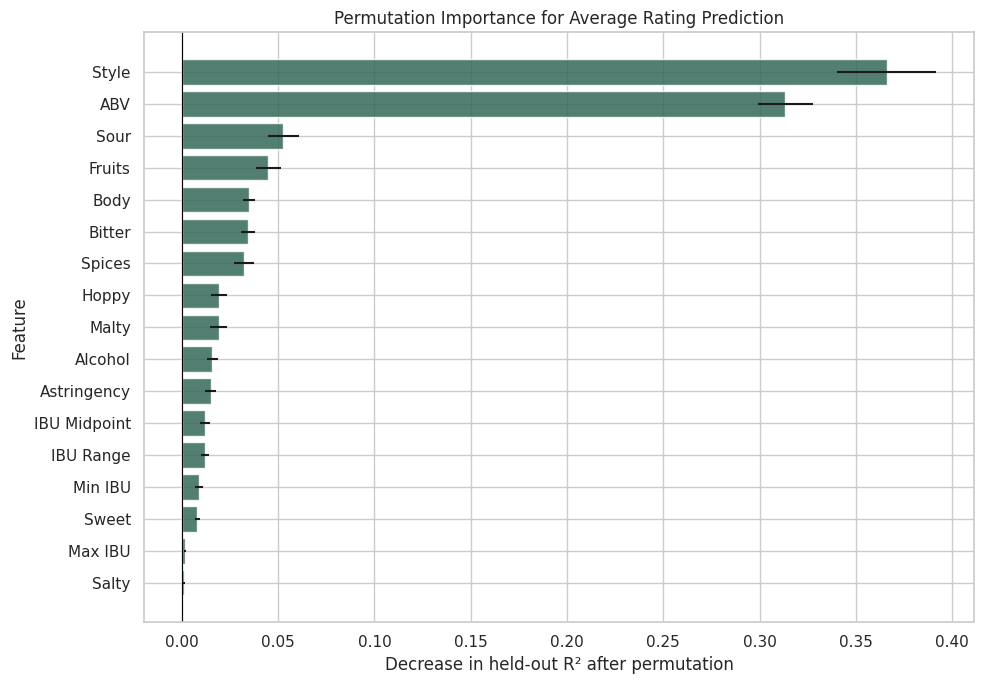

In [15]:
permutation = permutation_importance(
    rating_pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring='r2',
    n_jobs=-1
)

importance_df = pd.DataFrame({
    'Feature': model_features,
    'Importance mean': permutation.importances_mean,
    'Importance std': permutation.importances_std
}).sort_values('Importance mean', ascending=True)

display(importance_df.sort_values('Importance mean', ascending=False))

plt.figure(figsize=(10, 7))
plt.barh(
    importance_df['Feature'],
    importance_df['Importance mean'],
    xerr=importance_df['Importance std'],
    color='#356859',
    alpha=.85
)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Permutation Importance for Average Rating Prediction')
plt.xlabel('Decrease in held-out R² after permutation')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Thank you..pls upvote!!!!